# SentinelDesk — Exploratory Data Analysis

Goal: understand the ticket data well enough to design the **triage classifier**, the **escalation gate**, and the **RAG knowledge base**.

> **Leakage rule:** this notebook only reads `kb_train.parquet` (the 80% split). The holdout set is never inspected here except for its size.

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_colwidth", 120)

DATA = Path("../data/processed")
df = pd.read_parquet(DATA / "kb_train.parquet")
n_test = len(pd.read_parquet(DATA / "test_holdout.parquet", columns=["ticket_id"]))
print(f"KB/train rows: {len(df):,}   holdout rows: {n_test:,}")
df.head(3)

KB/train rows: 22,869   holdout rows: 5,718


,subject,body,answer,type,queue,priority,language,version,tag_1,tag_2,tag_3,tag_4,tag_5,tag_6,tag_7,tag_8,ticket_id
0,,"Kundenservice, ich möchte einen Vorfall melden, der mehrere Produkte betrifft, einschließlich PHP 8.0 und OBS Studio...","<name>, danke für die Meldung des Vorfalls, der mehrere Produkte betrifft. Wir werden die Serverauslastung sowie mög...",Incident,Technical Support,high,de,52,Performance,Outage,Disruption,Recovery,IT,Tech Support,NaN,NaN,TKT-00000
1,,"Sehr geehrter Kundenservice, ich möchte detaillierte Integrationsanleitungen für Oracle Database 19c innerhalb einer...","Sehr geehrter <name>, vielen Dank, dass Sie unseren Kundenservice kontaktiert haben. Wir freuen uns, Ihnen detaillie...",Request,Technical Support,high,de,52,Product,Documentation,Support,Integration,Configuration,NaN,NaN,NaN,TKT-00001
2,Issues with Brand Expansion,"Despite enhancing ad text and boosting the budget, engagement levels remain low.","I appreciate your concerns about low engagement, even after optimizing the ad copy and increasing the budget. To bet...",Incident,IT Support,high,en,52,Marketing,Campaign,Budget,Engagement,Brand Expansion,NaN,NaN,NaN,TKT-00002


## 1. Schema & missing values

In [ ]:
df["subject"] = df["subject"].replace("", np.nan)  # prepare_data filled nulls with ""
miss = df.isna().mean().mul(100).round(1).rename("% missing").to_frame()
miss[miss["% missing"] > 0].sort_values("% missing", ascending=False)

,% missing
tag_8,98.0
tag_7,92.9
tag_6,79.5
tag_5,49.0
subject,13.6
tag_4,10.8
tag_3,0.5
tag_2,0.1


In [ ]:
# Missing subjects by language — does the pipeline need to lean on the body more for one language?
df.groupby("language")["subject"].apply(lambda s: s.isna().mean() * 100).round(1).rename("% missing subject")

language
de    10.2
en    16.1
Name: % missing subject, dtype: float64

## 2. Target distributions (class imbalance)
Imbalance drives our metric (Macro-F1) and whether we need class weights.

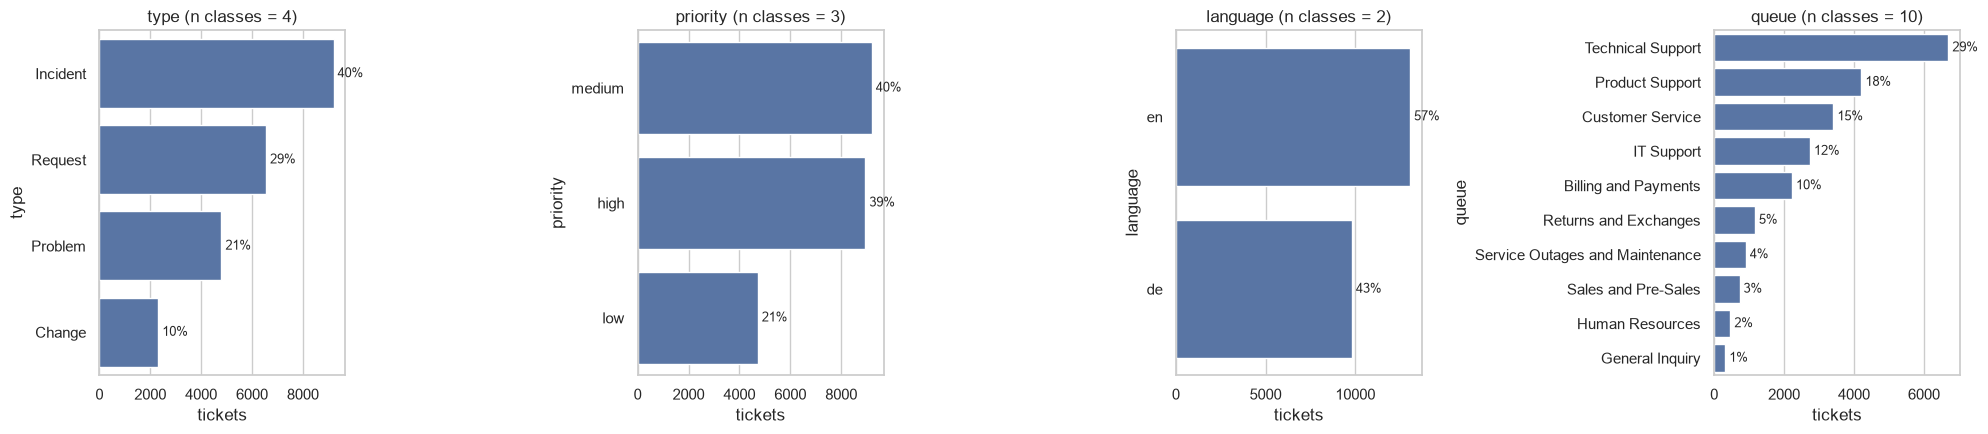

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, col in zip(axes, ["type", "priority", "language", "queue"]):
    vc = df[col].value_counts()
    sns.barplot(x=vc.values, y=vc.index, ax=ax, orient="h")
    ax.set_title(f"{col} (n classes = {len(vc)})"); ax.set_xlabel("tickets")
    for i, v in enumerate(vc.values):
        ax.text(v, i, f" {v/len(df):.0%}", va="center", fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
for col in ["type", "priority", "queue"]:
    vc = df[col].value_counts()
    print(f"{col:9s} imbalance ratio (largest/smallest): {vc.max()/vc.min():.1f}x")

type      imbalance ratio (largest/smallest): 4.0x
priority  imbalance ratio (largest/smallest): 1.9x
queue     imbalance ratio (largest/smallest): 21.1x


## 3. Priority × Type — sizing the escalation gate
Rule from the brief: `priority == high AND type == Incident` → escalate immediately.

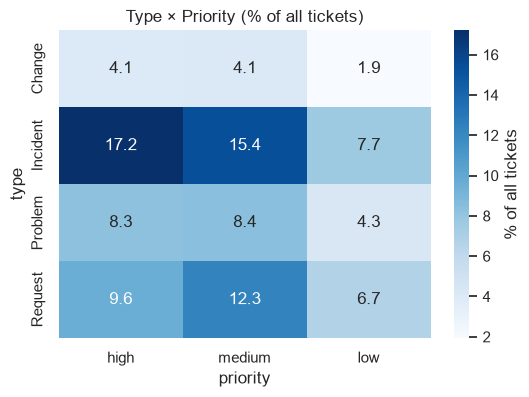

High-priority Incidents → hard escalation rate: 17.2% of tickets


In [ ]:
ct = pd.crosstab(df["type"], df["priority"], normalize="all").mul(100)[["high", "medium", "low"]]
plt.figure(figsize=(6, 4))
sns.heatmap(ct, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "% of all tickets"})
plt.title("Type × Priority (% of all tickets)"); plt.show()

hi_inc = ((df.priority == "high") & (df.type == "Incident")).mean()
print(f"High-priority Incidents → hard escalation rate: {hi_inc:.1%} of tickets")

In [ ]:
# Within each type, what share is high priority?
pd.crosstab(df["type"], df["priority"], normalize="index").mul(100).round(1)[["high", "medium", "low"]]

priority,high,medium,low
type,,,
Change,40.2,40.8,19.0
Incident,42.8,38.2,19.1
Problem,39.4,40.1,20.5
Request,33.5,43.0,23.5


## 4. Queue × Priority and Queue × Type
Which departments carry urgent work? Useful for routing and for per-queue thresholds.

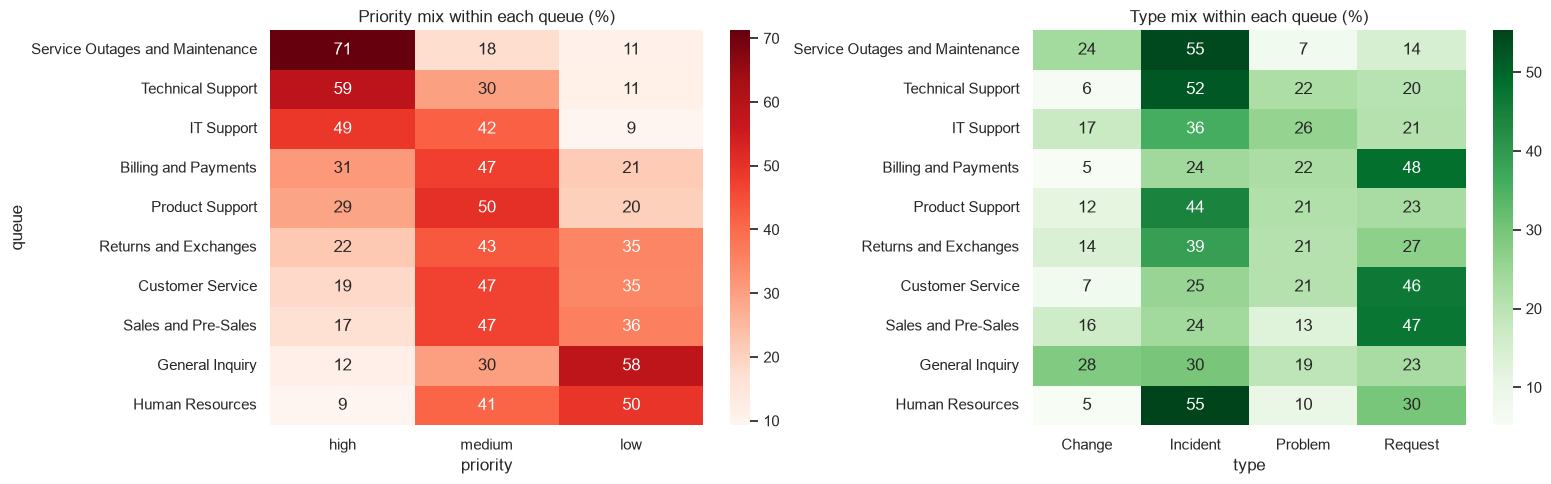

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
qp = pd.crosstab(df["queue"], df["priority"], normalize="index").mul(100)[["high", "medium", "low"]]
sns.heatmap(qp.sort_values("high", ascending=False), annot=True, fmt=".0f", cmap="Reds", ax=axes[0])
axes[0].set_title("Priority mix within each queue (%)")
qt = pd.crosstab(df["queue"], df["type"], normalize="index").mul(100)
sns.heatmap(qt.loc[qp.sort_values("high", ascending=False).index], annot=True, fmt=".0f", cmap="Greens", ax=axes[1])
axes[1].set_title("Type mix within each queue (%)"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

## 5. Language — is the label mix the same in EN and DE?
If distributions differ, the classifier could learn language as a shortcut.

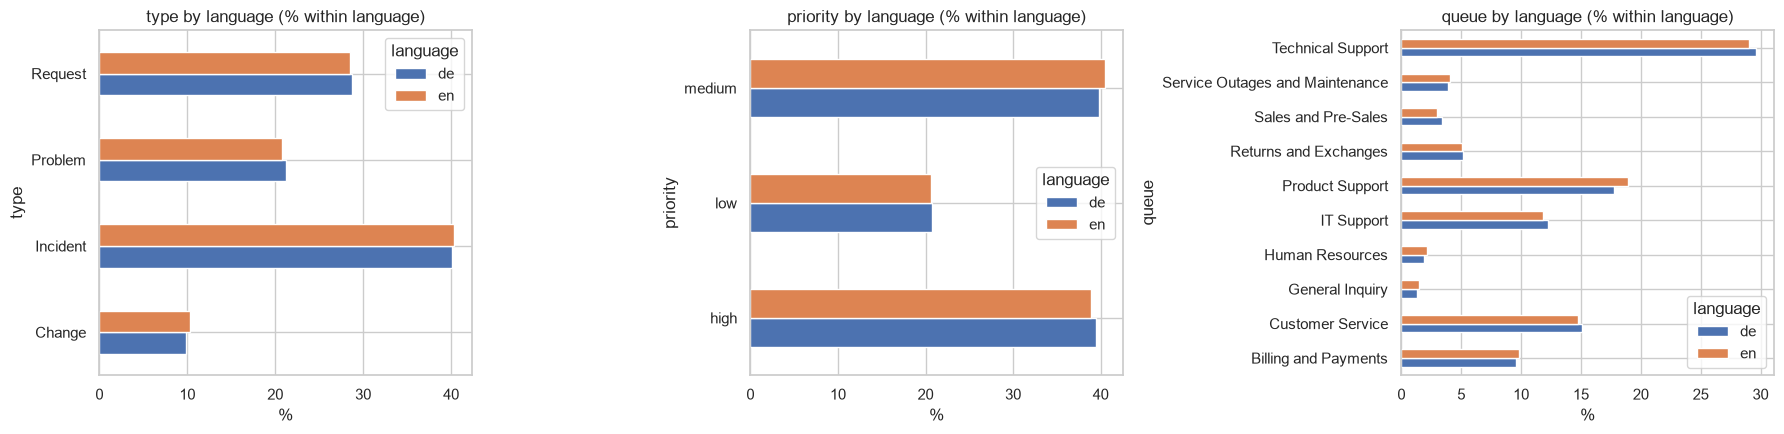

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col in zip(axes, ["type", "priority", "queue"]):
    t = pd.crosstab(df[col], df["language"], normalize="columns").mul(100)
    t.plot.barh(ax=ax); ax.set_title(f"{col} by language (% within language)"); ax.set_xlabel("%")
plt.tight_layout(); plt.show()

In [ ]:
# Chi-square-free quick check: max absolute gap (percentage points) between EN and DE per label
for col in ["type", "priority", "queue"]:
    t = pd.crosstab(df[col], df["language"], normalize="columns").mul(100)
    gap = (t["en"] - t["de"]).abs()
    print(f"{col:9s} largest EN/DE gap: {gap.max():.1f} pp ({gap.idxmax()})")

type      largest EN/DE gap: 0.5 pp (Problem)
priority  largest EN/DE gap: 0.7 pp (medium)
queue     largest EN/DE gap: 1.1 pp (Product Support)


## 6. Text length
Drives model choice (transformer max length) and chunking for embeddings.

In [ ]:
df["body_words"] = df["body"].fillna("").str.split().str.len()
df["answer_words"] = df["answer"].fillna("").str.split().str.len()
df["subject_words"] = df["subject"].fillna("").str.split().str.len()
print(df.groupby("language")[["subject_words", "body_words", "answer_words"]].describe(percentiles=[.5, .95]).T.round(0))

language                 de       en
subject_words count  9814.0  13055.0
              mean      4.0      5.0
              std       3.0      3.0
              min       0.0      0.0
              50%       4.0      5.0
              95%       9.0      9.0
              max      74.0     29.0
body_words    count  9814.0  13055.0
              mean     53.0     54.0
              std      29.0     27.0
              min       1.0      1.0
              50%      52.0     55.0
              95%      94.0     91.0
              max     166.0    168.0
answer_words  count  9814.0  13055.0
              mean     56.0     56.0
              std      27.0     26.0
              min       0.0      0.0
              50%      56.0     59.0
              95%      95.0     92.0
              max     121.0    135.0


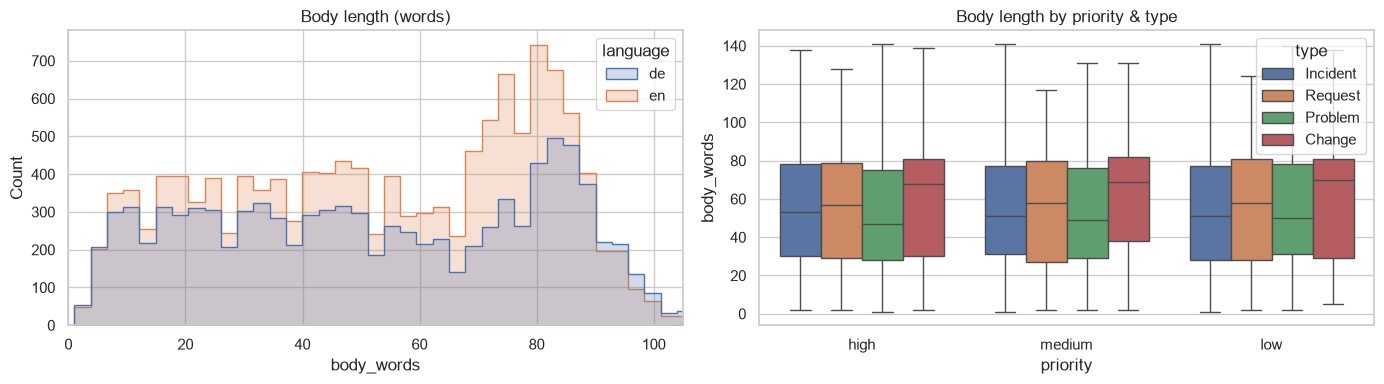

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df, x="body_words", hue="language", bins=60, ax=axes[0], element="step")
axes[0].set_xlim(0, df.body_words.quantile(.99)); axes[0].set_title("Body length (words)")
sns.boxplot(df, x="priority", y="body_words", hue="type", ax=axes[1], showfliers=False, order=["high", "medium", "low"])
axes[1].set_title("Body length by priority & type"); plt.tight_layout(); plt.show()

## 7. Tags — auxiliary signal
Tags are free-text keywords; they can help filter retrieval or explain clusters.

distinct tags: 1,137   avg tags/ticket: 4.7


/var/folders/j9/6p0sd66s6sqc88b29n1sdtfw0000gn/T/ipykernel_79367/1317071903.py:3: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  print(f"distinct tags: {tags.nunique():,}   avg tags/ticket: {df[tag_cols].notna().sum(1).mean():.1f}")


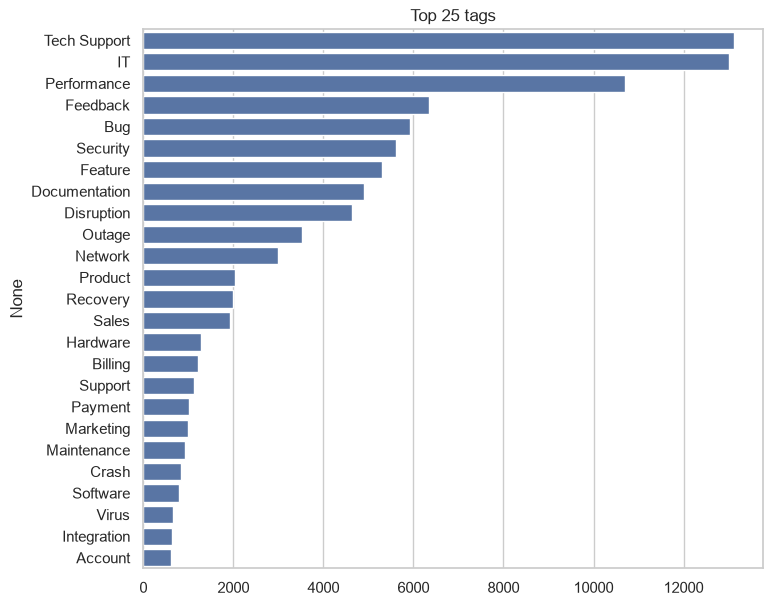

In [ ]:
tag_cols = [c for c in df.columns if c.startswith("tag_")]
tags = df[tag_cols].stack().str.strip()
print(f"distinct tags: {tags.nunique():,}   avg tags/ticket: {df[tag_cols].notna().sum(1).mean():.1f}")
top = tags.value_counts().head(25)
plt.figure(figsize=(8, 7)); sns.barplot(x=top.values, y=top.index, orient="h"); plt.title("Top 25 tags"); plt.show()

In [ ]:
# Top tags per queue
long = df[["queue"] + tag_cols].melt(id_vars="queue", value_name="tag").dropna()
(long.groupby("queue")["tag"].agg(lambda s: ", ".join(s.value_counts().head(5).index)).to_frame("top 5 tags"))

,top 5 tags
queue,
Billing and Payments,"Billing, Payment, Tech Support, IT, Feedback"
Customer Service,"IT, Tech Support, Feedback, Performance, Documentation"
General Inquiry,"Feedback, IT, Tech Support, Performance, Feature"
Human Resources,"IT, Tech Support, Performance, Security, Feedback"
IT Support,"IT, Tech Support, Performance, Bug, Disruption"
Product Support,"Tech Support, IT, Performance, Feedback, Bug"
Returns and Exchanges,"Tech Support, IT, Performance, Feedback, Bug"
Sales and Pre-Sales,"IT, Feedback, Tech Support, Feature, Documentation"
Service Outages and Maintenance,"IT, Tech Support, Disruption, Outage, Performance"


## 8. Urgency keywords vs. priority
Do words like *outage / down / urgent* actually signal high priority? Tells us whether a keyword rule adds anything over the classifier.

In [ ]:
kw = {
    "outage|down|ausfall|nicht erreichbar": "outage/down",
    "urgent|asap|immediately|dringend|sofort": "urgent",
    "vpn": "vpn",
    "password|passwort|login|anmeld": "login/password",
    "refund|invoice|billing|rechnung|erstattung": "billing",
    "hospital|patient|emr|krankenhaus": "healthcare",
}
text = (df["subject"].fillna("") + " " + df["body"].fillna("")).str.lower()
rows = []
for pat, name in kw.items():
    m = text.str.contains(pat, regex=True)
    rows.append({"keyword group": name, "tickets": m.sum(),
                 "% high when present": (df.loc[m, "priority"] == "high").mean() * 100,
                 "% high when absent": (df.loc[~m, "priority"] == "high").mean() * 100,
                 "top queue": df.loc[m, "queue"].mode().iat[0] if m.any() else ""})
pd.DataFrame(rows).round(1)

,keyword group,tickets,% high when present,% high when absent,top queue
0,outage/down,1368,62.9,37.6,Technical Support
1,urgent,1614,57.6,37.7,Technical Support
2,vpn,65,36.9,39.1,Technical Support
3,login/password,665,38.5,39.1,Technical Support
4,billing,1277,31.2,39.6,Billing and Payments
5,healthcare,3214,39.5,39.1,Technical Support


## 9. Duplicates & answer reuse — what does the RAG knowledge base look like?

In [ ]:
print(f"exact duplicate bodies: {df.duplicated('body').sum():,}")
print(f"exact duplicate answers: {df.duplicated('answer').sum():,}")
print(f"missing answers: {df['answer'].isna().sum():,}")
df.sample(3, random_state=1)[["ticket_id", "language", "type", "queue", "priority", "subject", "body", "answer"]]

exact duplicate bodies: 0
exact duplicate answers: 5
missing answers: 6


,ticket_id,language,type,queue,priority,subject,body,answer
3774,TKT-03774,en,Incident,IT Support,high,NaN,"A data breach incident has occurred, potentially compromising sensitive medical data systems due to a malware attack...",We appreciate your efforts in containing the malware attack and updating the scanning systems with Malwarebytes. To ...
10543,TKT-10543,de,Request,Product Support,low,Support for Blackboard Learn,Could you provide detailed information on the integration of Blackboard Learn with project management software syste...,We are pleased to assist with the integration of Blackboard Learn with project management software systems. We can p...
1541,TKT-01541,en,Request,Returns and Exchanges,medium,NaN,"I'm interested in learning about the SaaS features, project management, and scalability of your platform. Could you ...","I would be happy to provide information on the SaaS features, project management, and scalability of our platform. P..."


## 10. Is the `language` label trustworthy?
At demo time we must detect language from raw text, so check how often the label matches what a detector sees.

In [ ]:
from langdetect import detect, DetectorFactory
DetectorFactory.seed = 0
def detect_lang(t):
    try: return detect(t)
    except Exception: return "unk"
s = df.sample(2000, random_state=0).copy()
s["detected"] = s["body"].fillna("").map(detect_lang)
print(f"label == detected: {(s.detected == s.language).mean():.1%}")
pd.crosstab(s["language"], s["detected"])

label == detected: 87.6%


detected,da,de,en,es,fr,it,pt
language,,,,,,,
de,1,586,240,1,1,1,2
en,0,1,1166,0,1,0,0


## 11. Summary for triage design

In [ ]:
vc_t, vc_p = df.type.value_counts(normalize=True), df.priority.value_counts(normalize=True)
print(f"- {len(df):,} KB tickets; EN {df.language.eq('en').mean():.0%} / DE {df.language.eq('de').mean():.0%}")
print(f"- Missing subjects: {df.subject.isna().mean():.0%}  -> always build input as subject + body")
print(f"- Type: smallest class '{vc_t.idxmin()}' = {vc_t.min():.0%}  -> use class weights; report Macro-F1")
print(f"- Priority: high {vc_p['high']:.0%}, medium {vc_p['medium']:.0%}, low {vc_p['low']:.0%}")
print(f"- Hard-escalation rule (high Incident) fires on {hi_inc:.0%} of tickets")
print(f"- Queues: {df.queue.nunique()} classes, largest/smallest = {df.queue.value_counts().max()/df.queue.value_counts().min():.0f}x")
print(f"- Body length median {df.body_words.median():.0f} words, p95 {df.body_words.quantile(.95):.0f}  -> fits 256-512 token models")

- 22,869 KB tickets; EN 57% / DE 43%
- Missing subjects: 14%  -> always build input as subject + body
- Type: smallest class 'Change' = 10%  -> use class weights; report Macro-F1
- Priority: high 39%, medium 40%, low 21%
- Hard-escalation rule (high Incident) fires on 17% of tickets
- Queues: 10 classes, largest/smallest = 21x
- Body length median 54 words, p95 92  -> fits 256-512 token models
